# Matplotlib: the Object-Oriented API Explained

## Stop using `plt.plot()` and get better control over your charts

### The classic `pytplot()` interface

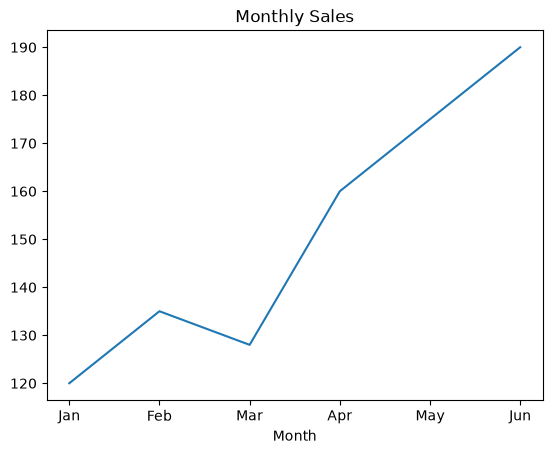

In [40]:
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 135, 128, 160, 175, 190]

plt.plot(months, sales)
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.show()

### The equivalent OO code

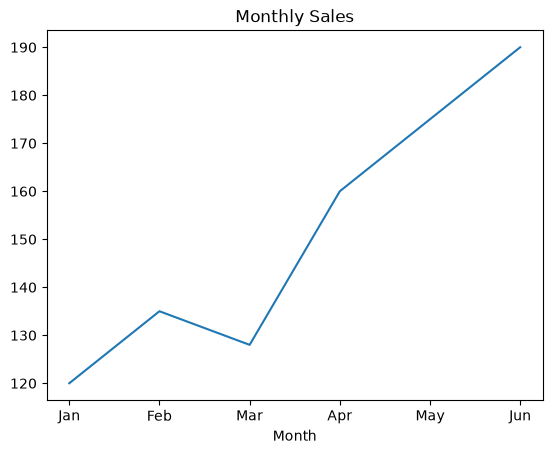

In [ ]:
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 135, 128, 160, 175, 190]

fig, ax = plt.subplots()
ax.plot(months, sales)
ax.set_title("Monthly Sales")
ax.set_xlabel("Month")
plt.show()

### Load the weather data and filter it for 2025 only

and define the list of months as m¡numbers and strings - we'll use these later

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

weather = pd.read_csv("./data/Heathrow.csv")

weather = weather[weather['Year']>=2025]
weather = weather[weather['Year'] < 2026]
weather = weather.round(1)
weather['Year'] = weather['Year'].astype('int')

month_numbers = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
weather

,Year,Month,Tmax,Tmin,AF,Rain,Sun
924,2025,1,7.3,1.4,10.0,80.4,51.9
925,2025,2,8.8,2.8,6.0,44.2,67.4
926,2025,3,14.1,3.9,7.0,4.4,187.9
927,2025,4,18.3,7.0,0.0,18.8,252.3
928,2025,5,21.1,10.1,0.0,15.4,225.5
929,2025,6,25.6,14.1,0.0,26.8,230.8
930,2025,7,25.8,15.8,0.0,48.4,190.3
931,2025,8,25.0,14.1,0.0,23.0,192.0
932,2025,9,20.3,11.1,0.0,48.8,170.9
933,2025,10,15.8,9.7,0.0,52.8,70.5


### Here is the traditional `pyplot` way of drawing a plot

Weather data

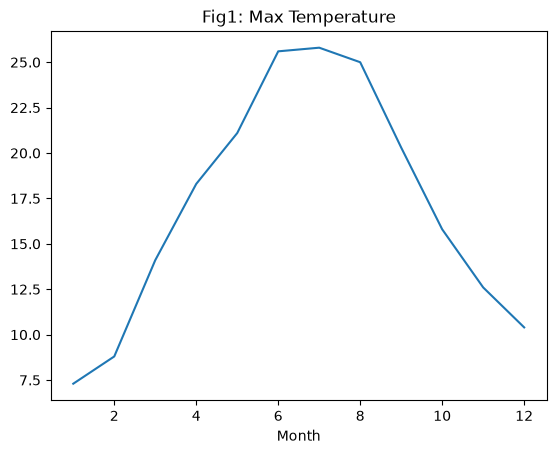

In [44]:
plt.plot(weather['Month'], weather['Tmax'])
plt.title("Fig1: Max Temperature")
plt.xlabel("Month")
plt.show()


### Here is the OO API equivalent - same figure

Weather data

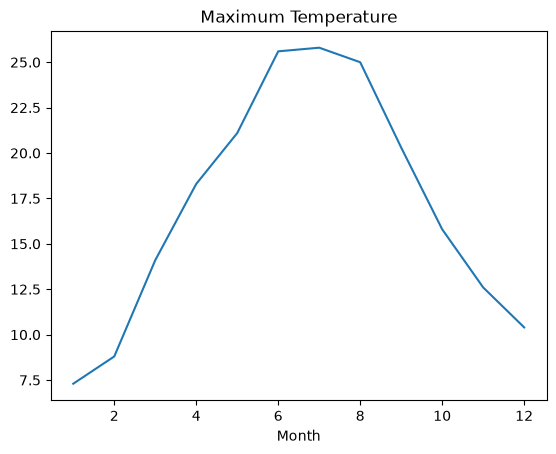

In [ ]:


fig, ax = plt.subplots()
ax.plot(weather['Month'], weather['Tmax'])
ax.set_title("Maximum Temperature")
ax.set_xlabel("Month")
plt.show()

### How to add a second plot to the axes with the OO API


and make sure all the months appear on the x-axis

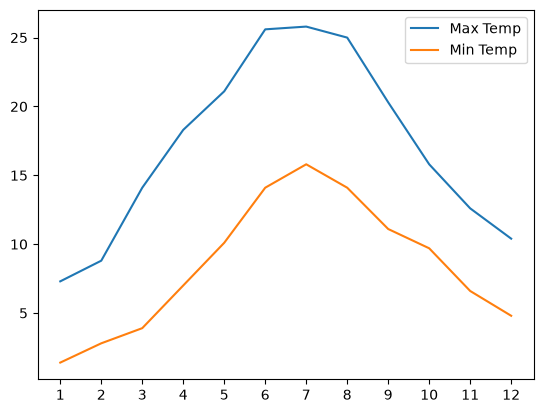

In [ ]:
fig, ax = plt.subplots()
ax.plot(weather['Month'], weather['Tmax'], label="Max Temp") 
ax.plot(weather['Month'], weather['Tmin'], label="Min Temp")
ax.set_xticks(month_numbers)
ax.legend()

plt.show()

### How to add a second plot (axes) to the figure

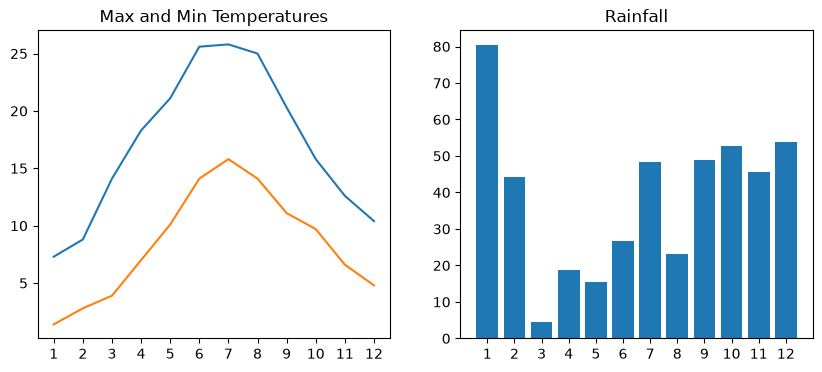

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(weather['Month'], weather['Tmax'])
axs[0].plot(weather['Month'], weather['Tmin'])
axs[0].set_xticks(month_numbers)
axs[0].set_title("Max and Min Temperatures")

axs[1].bar(weather['Month'], weather['Rain'])
axs[1].set_xticks(month_numbers)
axs[1].set_title("Rainfall")

plt.show()


### Add annotations to the figure - a header and footer

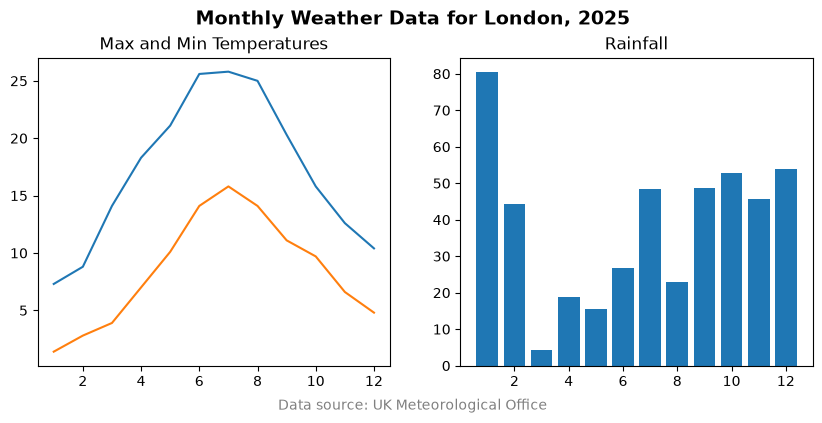

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(weather['Month'], weather['Tmax'])
axs[0].plot(weather['Month'], weather['Tmin'])
axs[0].set_title("Max and Min Temperatures")

axs[1].bar(weather['Month'], weather['Rain'])
axs[1].set_title("Rainfall")

fig.suptitle("Monthly Weather Data for London, 2025",
    fontsize=14,
    fontweight="bold",
    y=1
)

fig.text(
    0.5, 0,
    "Data source: UK Meteorological Office",
    ha="center",
    fontsize=10,
    color='grey'
)

plt.show()


### Add annotations to a plot (axes)

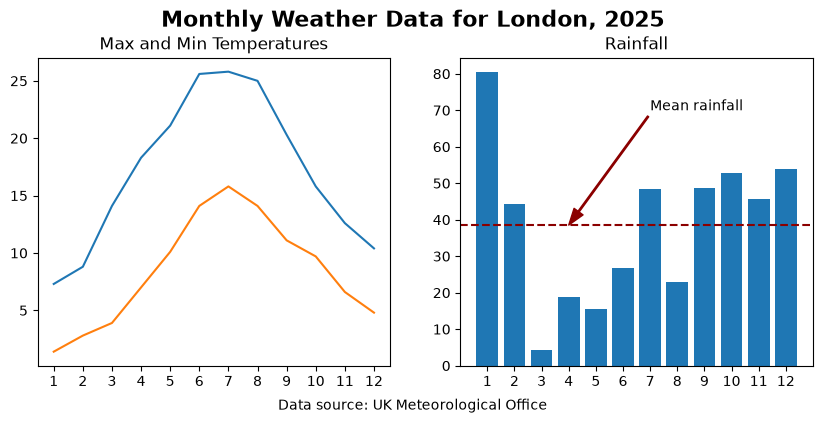

In [ ]:
mean_rain = weather['Rain'].mean()

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(weather['Month'], weather['Tmax'])
axs[0].plot(weather['Month'], weather['Tmin'])
axs[0].set_xticks(month_numbers)
axs[0].set_title("Max and Min Temperatures")

axs[1].bar(weather['Month'], weather['Rain'])
axs[1].set_xticks(month_numbers)
axs[1].axhline(y=mean_rain, color='darkred', linestyle="--")
axs[1].annotate('Mean rainfall', xy=(4, mean_rain), xytext=(7, 70),
            arrowprops=dict(color='darkred', width=1, headwidth=8))


axs[1].set_title("Rainfall")

fig.suptitle("Monthly Weather Data for London, 2025",
    fontsize=16,
    fontweight="bold",
    y=1
)

fig.text(
    0.5, 0,
    "Data source: UK Meteorological Office",
    ha="center",
    fontsize=10
)

plt.show()


### Add two more axes and format the title


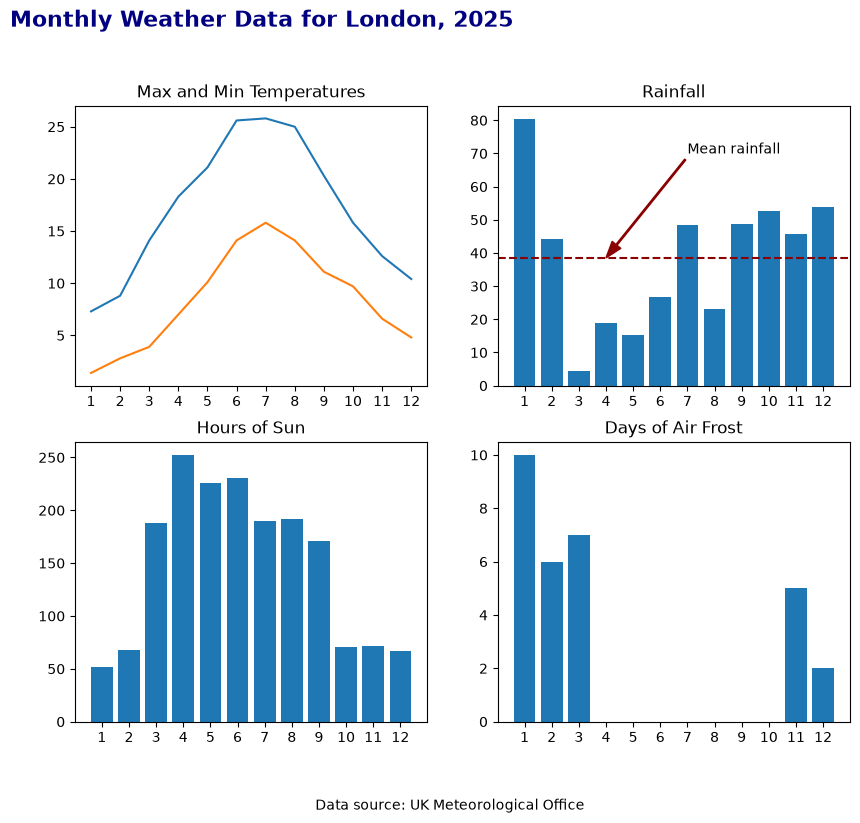

In [ ]:
mean_rain = weather['Rain'].mean()

fig, axs = plt.subplots(2, 2, figsize=(10, 8))

axs[0,0].plot(weather['Month'], weather['Tmax'])
axs[0,0].plot(weather['Month'], weather['Tmin'])
axs[0,0].set_xticks(month_numbers)
axs[0,0].set_title("Max and Min Temperatures")

axs[0,1].bar(weather['Month'], weather['Rain'])
axs[0,1].set_xticks(month_numbers)
axs[0,1].axhline(y=mean_rain, color='darkred', linestyle="--")
axs[0,1].annotate('Mean rainfall', xy=(4, mean_rain), xytext=(7, 70),
            arrowprops=dict(color='darkred', width=1, headwidth=8))
axs[0,1].set_title("Rainfall")

axs[1,0].bar(weather['Month'], weather['Sun'])
axs[1,0].set_xticks(month_numbers)
axs[1,0].set_title("Hours of Sun")
axs[1,1].bar(weather['Month'], weather['AF'])
axs[1,1].set_xticks(month_numbers)
axs[1,1].set_title("Days of Air Frost")


fig.suptitle("Monthly Weather Data for London, 2025",
    fontsize=16,
    fontweight="bold",
    color="navy",
    x=0.06,
    y=1,
    ha="left",
)

fig.text(
    0.5, 0,
    "Data source: UK Meteorological Office",
    ha="center",
    fontsize=10
)

plt.show()



### Format the plot titles and change the colours to distinguish the data types

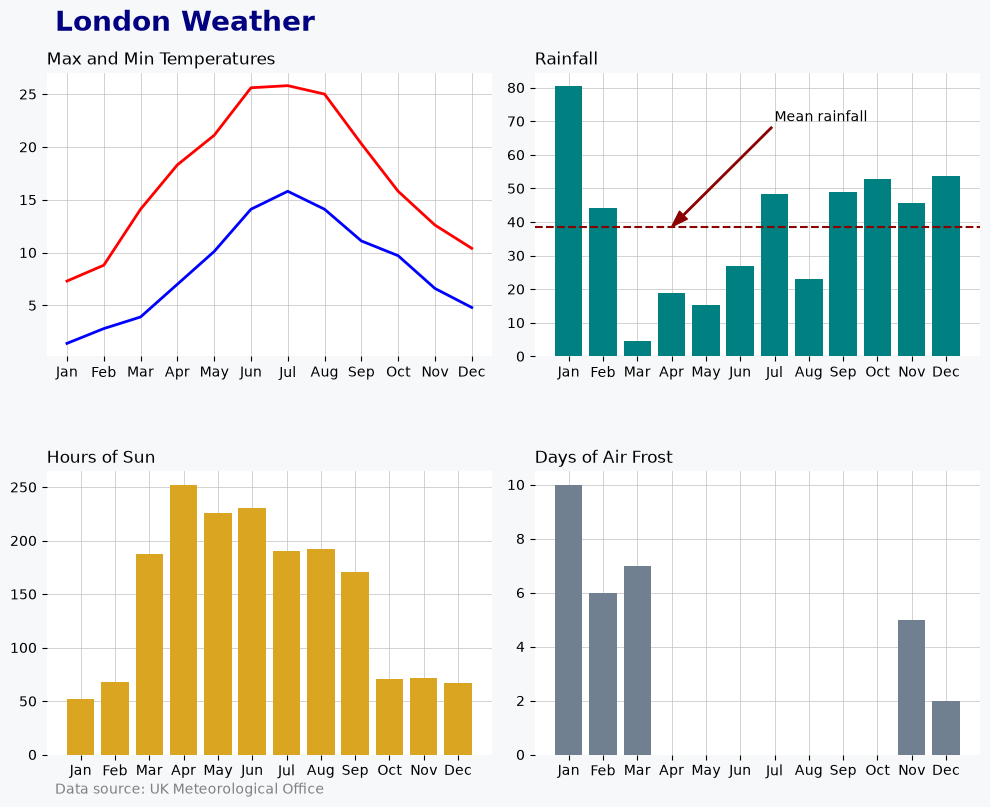

In [ ]:


mean_rain = weather['Rain'].mean()

fig, axs = plt.subplots(2, 2, figsize=(10, 8))

for i, ax in enumerate(axs.flat):
    ax.spines[:].set_visible(False)
    ax.grid(True, color="silver", linewidth=0.5)
    ax.set_axisbelow(True)
    ax.set_xticks(month_numbers, month_names)
    
fig.set_facecolor(color="#F7F8FA")
    
axs[0,0].plot(weather['Month'], weather['Tmax'], linewidth='2',color='red')
axs[0,0].plot(weather['Month'], weather['Tmin'], linewidth='2', color='blue')
axs[0,0].set_title("Max and Min Temperatures", loc='left')

axs[0,1].bar(weather['Month'], weather['Rain'], color='teal')
axs[0,1].axhline(y=mean_rain, color='darkred', linestyle="--")
axs[0,1].annotate('Mean rainfall', xy=(4, mean_rain), xytext=(7, 70),
            arrowprops=dict(color='darkred', width=1, headwidth=8))
axs[0,1].set_title("Rainfall", loc='left')

axs[1,0].bar(weather['Month'], weather['Sun'], color='goldenrod')
axs[1,0].set_title("Hours of Sun", loc='left')
axs[1,1].bar(weather['Month'], weather['AF'], color='slategrey')
axs[1,1].set_title("Days of Air Frost", loc='left')


fig.suptitle("London Weather",
    fontsize=20,
    fontweight="bold",
    color="navy",
    x=0.06,
    ha="left")

fig.text(
    0.06, 0,
    "Data source: UK Meteorological Office",
    color='grey',
    ha="left",
    fontsize=10
)

# Add some horizontal padding between subplots
fig.tight_layout(h_pad=5.0)

plt.show()

